In [37]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate
import scipy.interpolate as interpolate
from scipy import optimize
from scipy.integrate import solve_ivp
from scipy import signal

# Exercises

For the exam, please complete two of these exercise (don't pick both Q1 and Q2, too easy)

## Q1: Simple numerical integral

Numerical integration methods work differently depending on whether you have the analytic function available (in which case you can evaluate it freely at any point you please) or if it is sampled for you.

Consider the function $f(x) = e^{-x^2}$.  We want to integrate this from $[-5, 5]$.  The
analytic integral is not easily obtained.  Use `integrate.quad` to do the integration.

In [38]:
def f_true(x):
    return np.exp(-x**2)

In [39]:
I_quad, err_quad = integrate.quad(f_true, -5.0, 5.0)

In [40]:
print("integral =", I_quad)
print("estimated quadrature error =", err_quad)

integral = 1.7724538509027912
estimated quadrature error = 4.6261378229003154e-14


Consider now that you have data that represents a function sampled a `N` points, but you don't know the analytic form of the function.  Here, we create the sampling from a uniform distribution

In [41]:
N = 32
x = np.linspace(-5, 5, N)
f = np.exp(-x**2)
f

array([1.38879439e-11, 3.15061953e-10, 5.80457065e-09, 8.68481106e-08,
       1.05527775e-06, 1.04133225e-05, 8.34503173e-05, 5.43103745e-04,
       2.87047478e-03, 1.23208538e-02, 4.29481052e-02, 1.21580337e-01,
       2.79510942e-01, 5.21855680e-01, 7.91258065e-01, 9.74320895e-01,
       9.74320895e-01, 7.91258065e-01, 5.21855680e-01, 2.79510942e-01,
       1.21580337e-01, 4.29481052e-02, 1.23208538e-02, 2.87047478e-03,
       5.43103745e-04, 8.34503173e-05, 1.04133225e-05, 1.05527775e-06,
       8.68481106e-08, 5.80457065e-09, 3.15061953e-10, 1.38879439e-11])

Compute the integral of this sampled function using Simpson's method (`integrate.simps`).  Now, vary the number of sample points (try 64, 128, ...) and see how the answer changes.  Simpson's method is 4-th order accurate, which means that the error should decrease by $2^4$ when we double the number of sample points.

In [42]:
Ns = np.array([32, 64, 128, 256, 512])
errors = []

In [43]:
for N in Ns:
    x = np.linspace(-5, 5, N)
    f = np.exp(-x**2)

    I_simpson = integrate.simpson(f, x=x)
    error = abs(I_simpson - I_quad)
    errors.append(error)

    print("N =", N, " integral =", I_simpson, " error =", error)

N = 32  integral = 1.7724538507774263  error = 1.253648296284382e-10
N = 64  integral = 1.7724538509012102  error = 1.580957587066223e-12
N = 128  integral = 1.7724538509027423  error = 4.884981308350689e-14
N = 256  integral = 1.7724538509027887  error = 2.4424906541753444e-15
N = 512  integral = 1.7724538509027907  error = 4.440892098500626e-16


In [44]:
errors = np.array(errors)

Make a plot of the error (compared to the quadrature result) vs. N

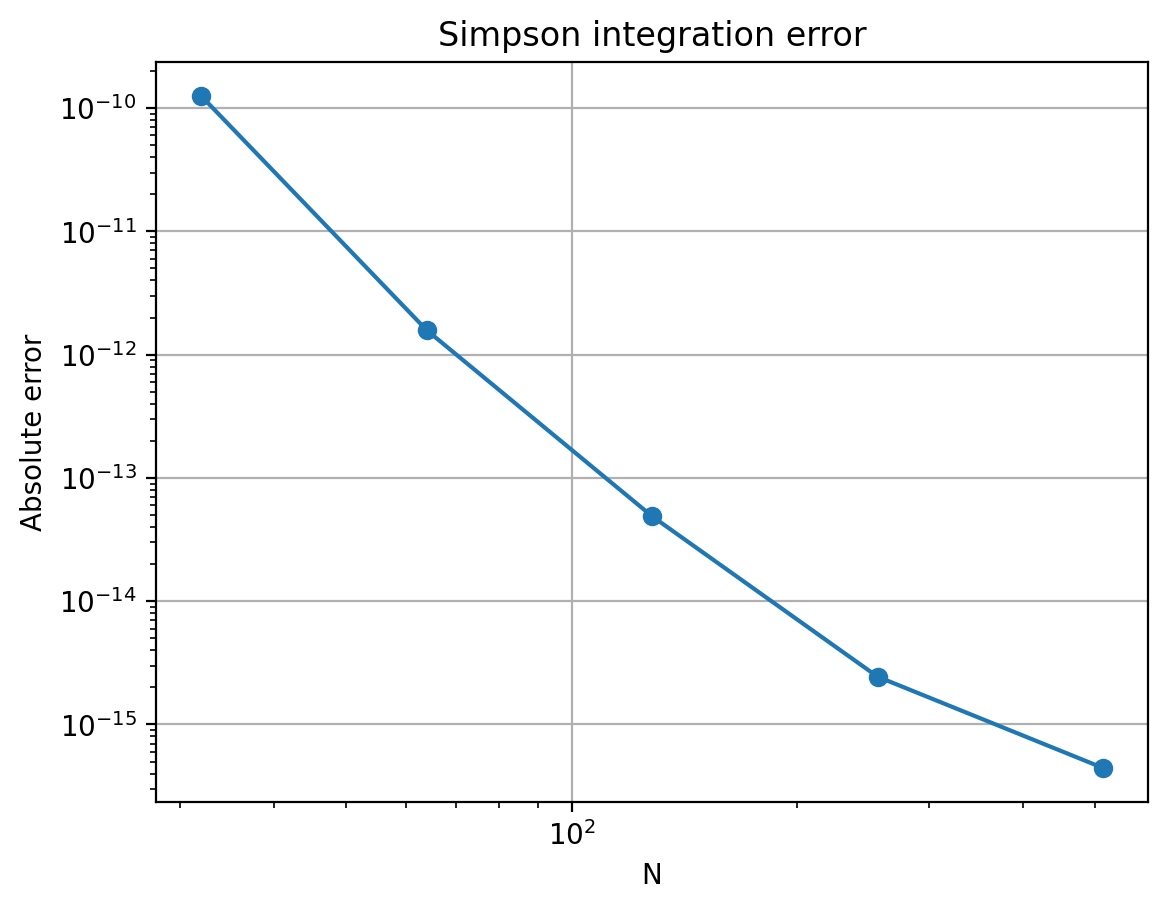

In [46]:
fig, ax = plt.subplots(dpi = 200)
ax.loglog(Ns, errors, "o-")
ax.set_xlabel("N")
ax.set_ylabel("Absolute error")
ax.set_title("Simpson integration error")
ax.grid(True)

plt.show()

## Q2: Interpolation error

There are a large number of different interpolation schemes available through scipy.  Let's test them out.

Create a python function, $f(x)$, that is your true function (make it complicated!).  Now create $N$ samples of it (either regularly spaced or irregularly spaced).

Try some of the different interpolation routines.  `interpolate.interp1d` takes a `kind` argument that lets you choose the order of the interpolation.  Measure the error in the method, by comparing the interpolated result with the actual function value.  

Then do the same cubic splines (look at `CubicSpline`)

Plot the resulting interpolant.

In [47]:
def f_true(x):
    return np.sin(2*x) + 0.3*np.cos(5*x) + 0.05*x**3

In [48]:
N = 12
x_sample = np.linspace(0, 2*np.pi, N)
y_sample = f_true(x_sample)

x_fine = np.linspace(0, 2*np.pi, 1000)
y_true = f_true(x_fine)

In [49]:
linear = interpolate.interp1d(x_sample, y_sample, kind="linear")
quadratic = interpolate.interp1d(x_sample, y_sample, kind="quadratic")
cubic = interpolate.interp1d(x_sample, y_sample, kind="cubic")
spline = interpolate.CubicSpline(x_sample, y_sample)

In [50]:
y_linear = linear(x_fine)
y_quadratic = quadratic(x_fine)
y_cubic = cubic(x_fine)
y_spline = spline(x_fine)

In [51]:
print("max error linear   =", np.max(np.abs(y_linear - y_true)))
print("max error quadratic=", np.max(np.abs(y_quadratic - y_true)))
print("max error cubic    =", np.max(np.abs(y_cubic - y_true)))
print("max error spline   =", np.max(np.abs(y_spline - y_true)))

max error linear   = 0.3624138807960147
max error quadratic= 0.2937160551611413
max error cubic    = 0.4572165833524835
max error spline   = 0.4572165833524817


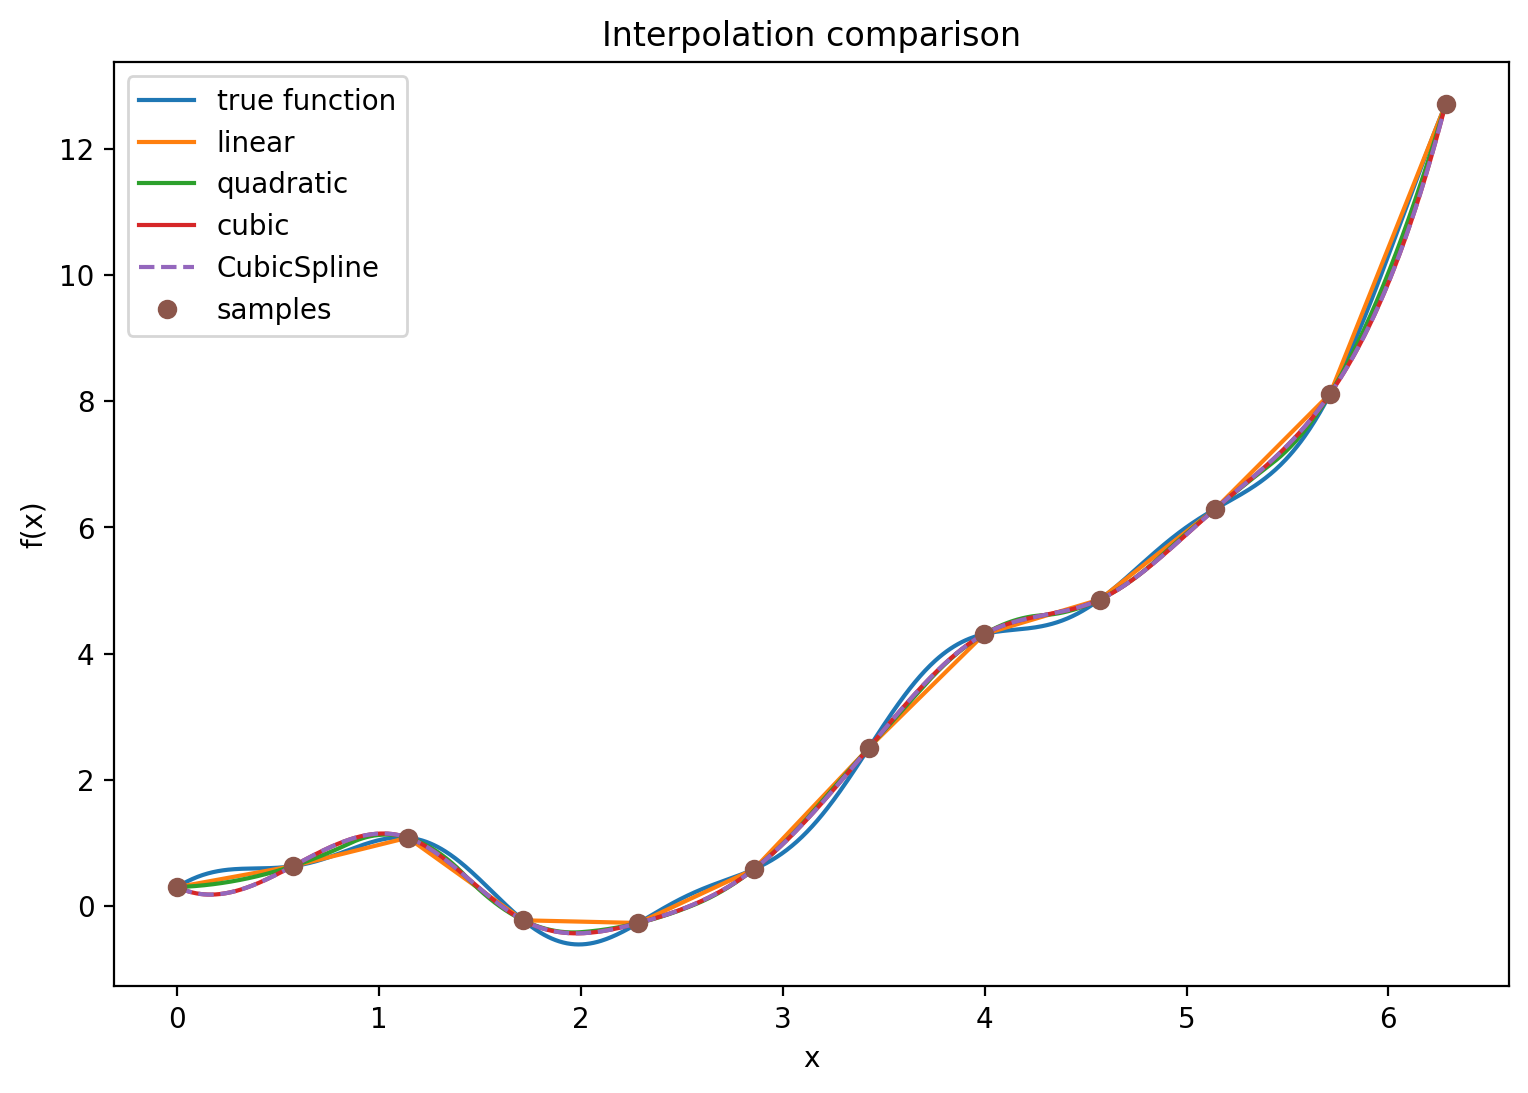

In [53]:
fig, ax = plt.subplots(figsize=(9, 6), dpi = 200)

ax.plot(x_fine, y_true, label="true function")
ax.plot(x_fine, y_linear, label="linear")
ax.plot(x_fine, y_quadratic, label="quadratic")
ax.plot(x_fine, y_cubic, label="cubic")
ax.plot(x_fine, y_spline, "--", label="CubicSpline")
ax.plot(x_sample, y_sample, "o", label="samples")

ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.set_title("Interpolation comparison")
ax.legend()

plt.show()

## Q3: Basins of attraction

Consider the function

$$q(x) = x^3 - 2x^2 - 11x + 12$$

This has 3 roots has you should find them all. This equation is known to cause problems for some root-finding methods because it exhibits [basis of attraction](https://en.wikipedia.org/wiki/Newton%27s_method#Basins_of_attraction) -- very closely spaced initial guesses leave to very different roots.

Find all three roots using both `optimize.brentq` and `optimize.root`.

In [54]:
def q(x):
    return x**3 - 2*x**2 - 11*x + 12

In [55]:
root1_brent = optimize.brentq(q, -4, -2)
root2_brent = optimize.brentq(q, 0, 2)
root3_brent = optimize.brentq(q, 3, 5)

print("brentq roots:")
print(root1_brent, root2_brent, root3_brent)

brentq roots:
-3.0 0.999999999999994 4.0


In [56]:
guesses = [-4.0, 0.5, 3.5]

print("\noptimize.root results:")
for guess in guesses:
    result = optimize.root(lambda x: q(x), guess)
    print("initial guess =", guess, " root =", result.x[0])


optimize.root results:
initial guess = -4.0  root = -3.0
initial guess = 0.5  root = 1.0
initial guess = 3.5  root = 4.0


In [57]:
print("\nClosely spaced initial guesses:")
for guess in np.linspace(-1.0, 3.0, 9):
    result = optimize.root(lambda x: q(x), guess)
    print("guess =", guess, " -> ", result.x[0])


Closely spaced initial guesses:
guess = -1.0  ->  4.0
guess = -0.5  ->  1.0
guess = 0.0  ->  1.0000000000000002
guess = 0.5  ->  1.0
guess = 1.0  ->  1.0
guess = 1.5  ->  1.000000000000003
guess = 2.0  ->  1.0000000000000004
guess = 2.5  ->  -3.0
guess = 3.0  ->  3.9999999999999467


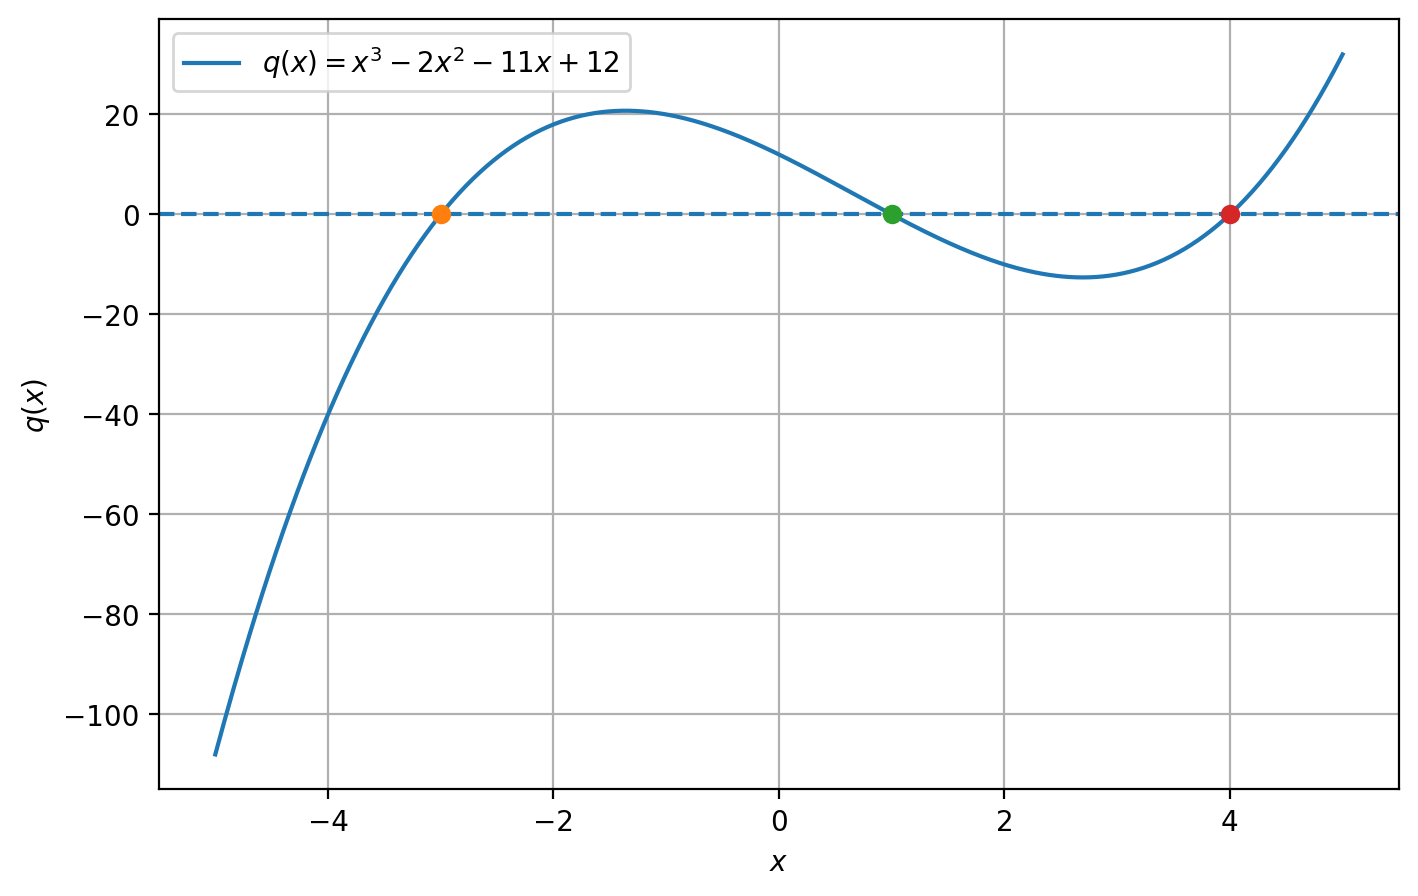

In [58]:
x = np.linspace(-5, 5, 500)
y = q(x)

plt.figure(figsize=(8, 5), dpi = 200)

plt.plot(x, y, label=r"$q(x)=x^3-2x^2-11x+12$")
plt.axhline(0, linestyle="--")

roots = [root1, root2, root3]

for r in roots:
    plt.plot(r, 0, "o", markersize=6)

plt.xlabel("$x$")
plt.ylabel("$q(x)$")
plt.grid(True)
plt.legend()
plt.show()

## Q5: Planetary orbits

We want to consider planetary orbits.  To do this, we need to solve Newton's second law together with Newton's law of gravity.  If we restrict ourselves to the x-y plane, then there are 4 quantities we need to solve for: $x$, $y$, $v_x$, and $v_y$.  These evolve according to:

\begin{align*}
\frac{dx}{dt} &= v_x \\
\frac{dy}{dt} &= v_y \\
\frac{dv_x}{dt} &= a_x = -\frac{GM_\star x}{r^3} \\
\frac{dv_y}{dt} &= a_y = -\frac{GM_\star y}{r^3}
\end{align*}

To integrate these forward in time, we need an initial condition for each quantity.  We'll setup our system such that the Sun is at the origin (that will be one focus), and the planet begins at perihelion and orbits counterclockwise. 

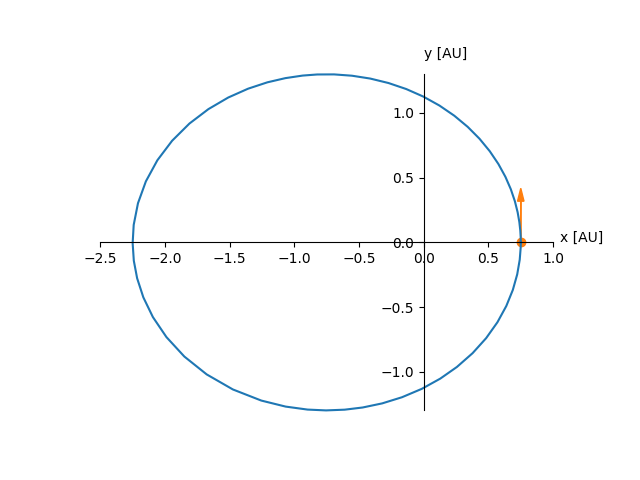

The distance of perihelion from the focus is:

$$r_p = a (1 - e)$$

where $a$ is the semi-major axis and $e$ is the eccentricity.  The perihelion velocity is all in the $y$ direction and is:

$$v_y = v_p = \sqrt{\frac{GM_\star}{a} \frac{1+e}{1-e}}$$

We'll work in units of AU, years, and solar masses, in which case, $GM_\star = 4\pi^2$ (for the Sun).  

Your initial conditions should be:

  * $x(t=0) = r_p$
  * $y(t=0) = 0$
  * $v_x(t=0) = 0$
  * $v_y(t=0) = v_p$

Use the scipy ODE integration methods to integrate an orbit and plot it

In [59]:
GM = 4*np.pi**2

In [60]:
def orbit_rhs(t, Y):
    x, y, vx, vy = Y

    r = np.sqrt(x**2 + y**2)

    ax = -GM * x / r**3
    ay = -GM * y / r**3

    return [vx, vy, ax, ay]

In [61]:
a = 1.0
e = 0.0167

rp = a * (1 - e)
vp = np.sqrt(GM / a * (1 + e) / (1 - e))

Y0 = [rp, 0.0, 0.0, vp]

t_eval = np.linspace(0, 1.0, 1000)

In [62]:
solution = solve_ivp(
    orbit_rhs,
    [0.0, 1.0],
    Y0,
    t_eval=t_eval,
    rtol=1.e-9,
    atol=1.e-11
)

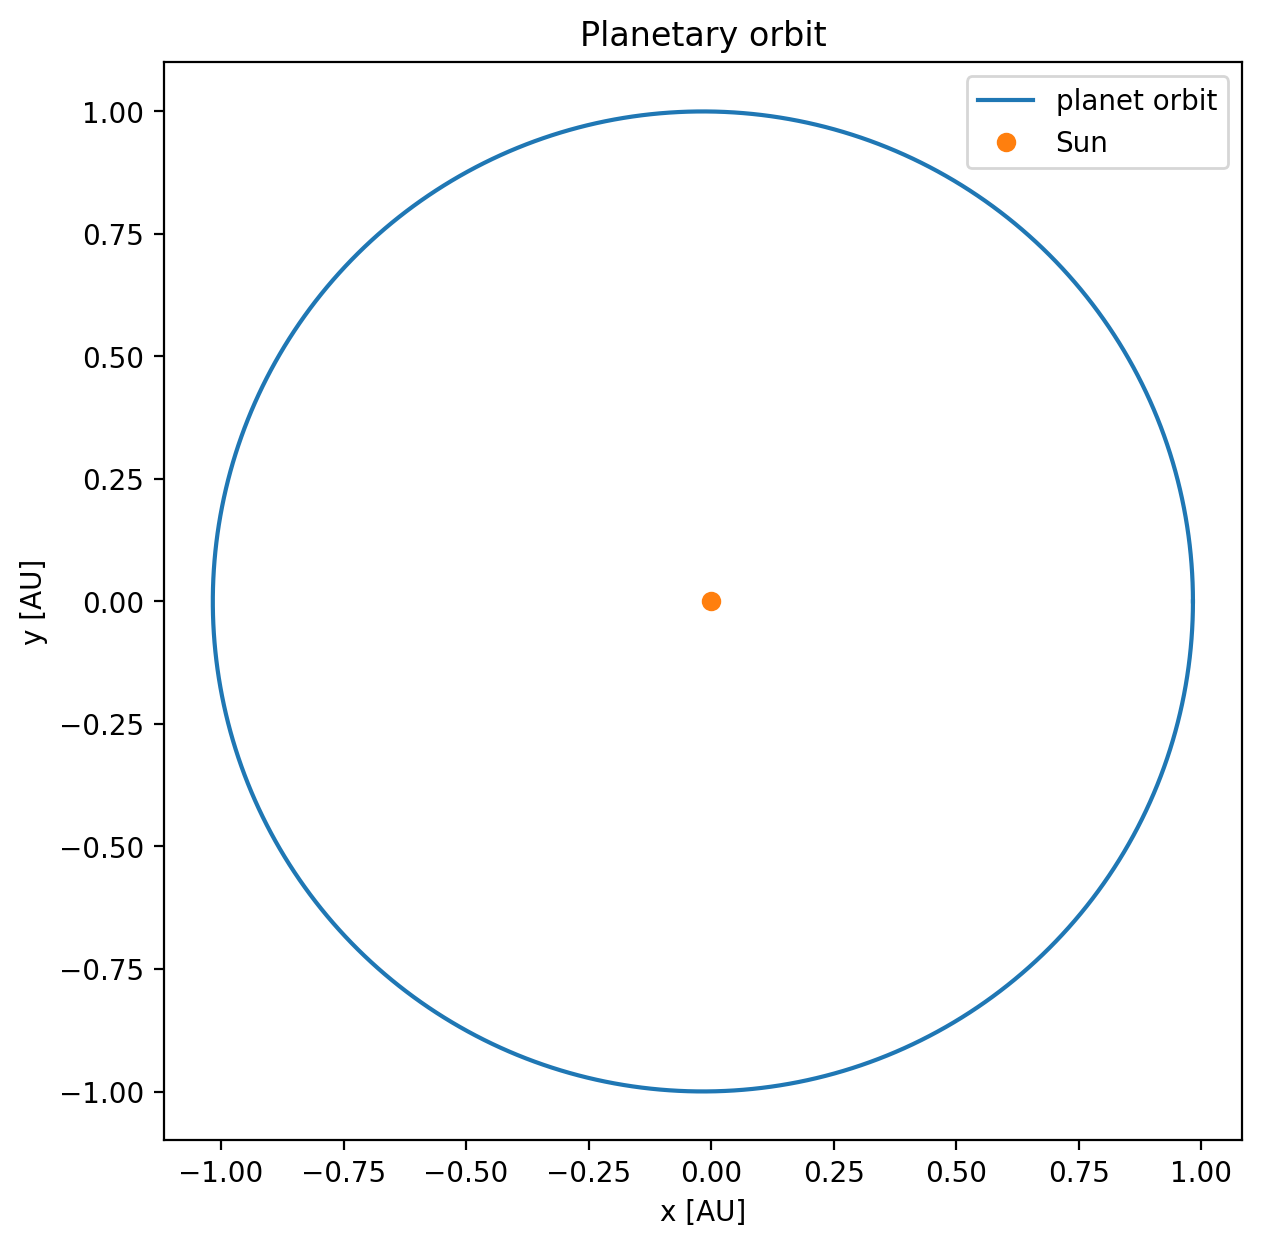

In [63]:
fig, ax = plt.subplots(figsize=(7, 7), dpi = 200)

ax.plot(solution.y[0], solution.y[1], label="planet orbit")
ax.plot(0, 0, "o", label="Sun")

ax.set_xlabel("x [AU]")
ax.set_ylabel("y [AU]")
ax.set_aspect("equal")
ax.set_title("Planetary orbit")
ax.legend()

plt.show()

## Q7: Noisy signal

A convolution is defined as:  

\begin{equation}  
  (f \star g)(t) \equiv \int_{-\infty}^{\infty} f(\tau) g(t - \tau) d\tau \tag{1}  
\end{equation}  

It is easy to compute this with FFTs, via the _convolution theorem_,  

\begin{equation}  
  \mathcal{F}\{f \star g\} = \mathcal{F}\{f\} \, \mathcal{F}\{g\} \tag{2}  
\end{equation}  

That is: the Fourier transform of the convolution of $f$ and $g$ is simply the product of the individual transforms of $f$ and $g$. This allows us to compute the convolution via multiplication in Fourier space and then take the inverse transform, $\mathcal{F}^{-1}\{\}$, to recover the convolution in real space:

\begin{equation}  
  f \star g = \mathcal{F}^{-1}\{ \mathcal{F}\{f\} \, \mathcal{F}\{g\}\} \tag{3}  
\end{equation}  

A common use of a convolution is to smooth noisy data, for example by convolving noisy data with a Gaussian. We'll do that here.


Here's some noisy data we'll work with

In [64]:
def fdata(x, L):
    A = L/10.0
    return 2*np.sin(2*np.pi*x/L) + x*(L-x)**2/L**3 * np.cos(x) + \
           5*x*(L-x)/L**2 + A/2 + 0.1*A*np.sin(13*np.pi*x/L)

In [65]:
N = 2048
L = 50.0
x = np.linspace(0, L, N, endpoint=False)
orig = fdata(x, L)
noisy = orig + 0.5*np.random.randn(N)

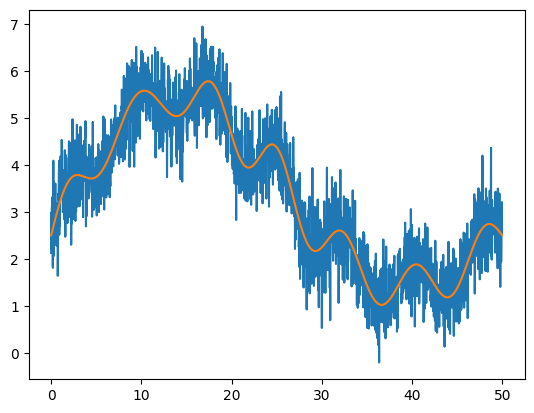

In [66]:
plt.plot(x, noisy)
plt.plot(x, orig)

SciPy provides a convolution function `scipy.signal.convolve()` that can do the convolution for us directly.  To smooth the data, we want to use a Gaussian, which can be produced by `scipy.signal.windows.gaussian()`.

Convolve the noisy data with a Gaussian and plot the result together with the original data `orig`.  You'll need to play with the width of the Gaussian to get a nice smoothing.  You also will need to normalize the Gaussian so that it sums to 1, otherwise, your convolved data will be shifted verfically from the original function.

In [67]:
width = 25
gaussian = signal.windows.gaussian(151, std=width)

In [68]:
gaussian = gaussian / np.sum(gaussian)
smoothed = signal.convolve(noisy, gaussian, mode="same")

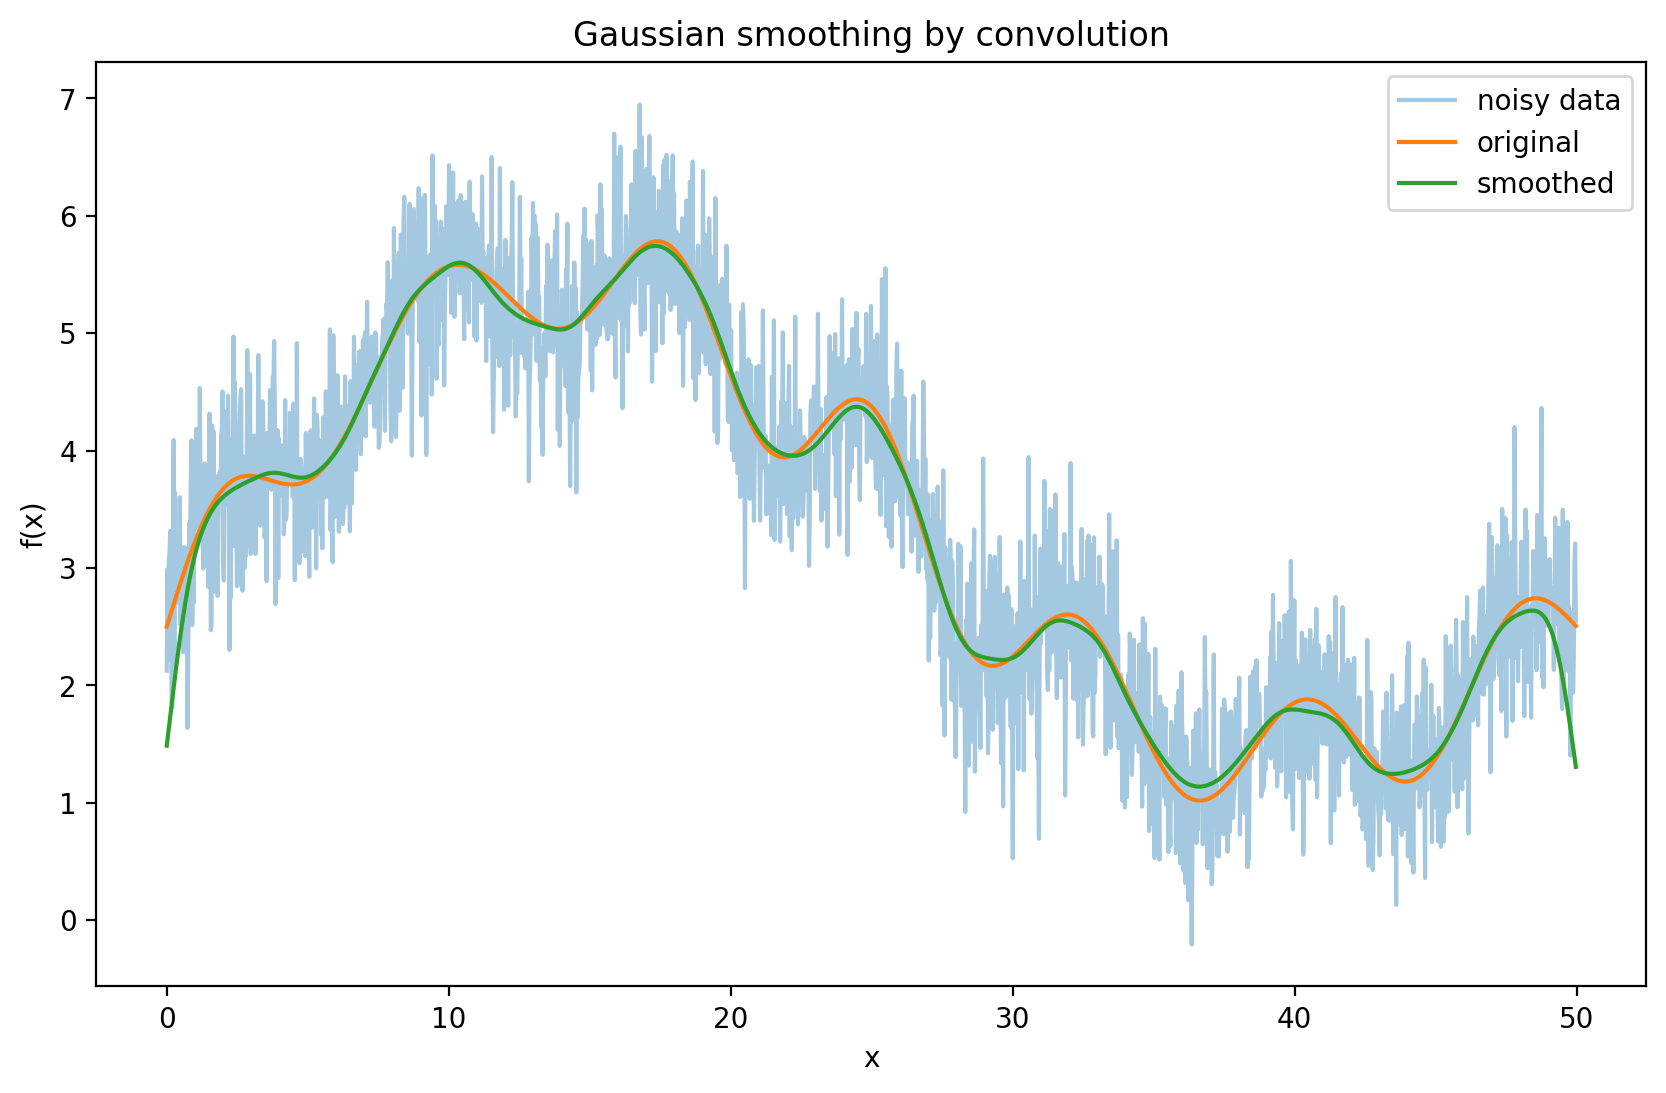

In [69]:
fig, ax = plt.subplots(figsize=(10, 6), dpi = 200)

ax.plot(x, noisy, alpha=0.4, label="noisy data")
ax.plot(x, orig, label="original")
ax.plot(x, smoothed, label="smoothed")

ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.set_title("Gaussian smoothing by convolution")
ax.legend()

plt.show()